In [1]:
%matplotlib inline
import json
import matplotlib.pyplot as plt
import pandas as pd
from migracoast_ml.config import FEATURE_NAMES
from migracoast_ml.dataset import load_training_table
from migracoast_ml.models.train import METRICS_PATH, MODEL_PATH
from migracoast_ml.models.scoring import RiskScorer

table = load_training_table()
metadata = json.loads(METRICS_PATH.read_text())
scorer = RiskScorer.load(MODEL_PATH)
print(f"Winner: {metadata['winner']}, cells: {metadata['n_cells']}")

Winner: gradient_boosting, cells: 8494


In [2]:
metrics = pd.DataFrame(metadata["metrics"])
metrics[["model", "rmse_mean", "rmse_std", "r2_mean",
         "coastal_rmse_mean", "coastal_spearman_mean"]]

,model,rmse_mean,rmse_std,r2_mean,coastal_rmse_mean,coastal_spearman_mean
0,ridge,1.396112,0.145645,0.435537,2.088819,0.628426
1,gradient_boosting,1.102460,0.050852,0.646189,1.530485,0.795391
2,neural_net,1.140952,0.060118,0.620794,1.587170,0.785349


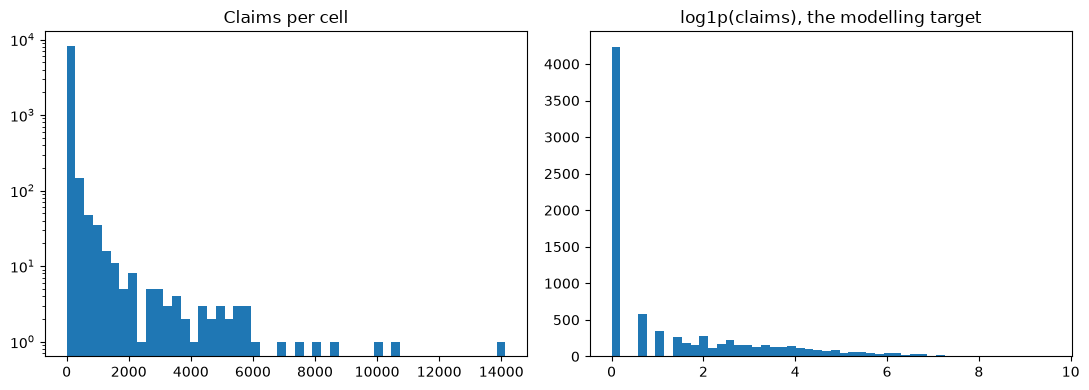

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(table["claim_count"], bins=50)
axes[0].set_yscale("log")
axes[0].set_title("Claims per cell")
axes[1].hist(table["target"], bins=50)
axes[1].set_title("log1p(claims), the modelling target")
plt.tight_layout()

,feature,importance_mean,importance_std
0,storm_events_per_year,0.401535,0.009469
1,elev_p10,0.216901,0.005062
2,coast_km,0.215213,0.006155
3,flood_events_per_year,0.159261,0.002960
4,slr_2100_ft,0.124761,0.003610
5,slr_2050_ft,0.057791,0.000933
6,elev_min,0.054514,0.002355
7,elev_mean,0.051271,0.001399
8,frac_below_5m,0.020904,0.000426
9,land_fraction,0.007201,0.000300


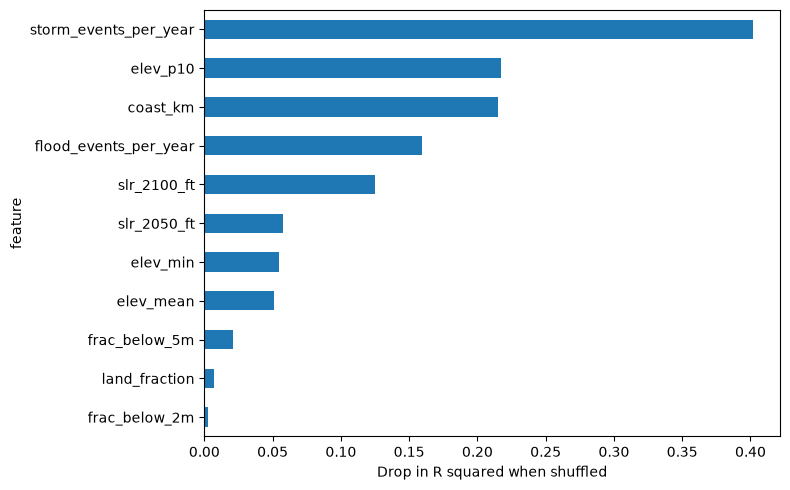

In [4]:
from migracoast_ml.models.explain import permutation_importance_table

importance = permutation_importance_table(
    scorer.model, table[list(FEATURE_NAMES)], table["target"], n_repeats=5
)
importance.plot.barh(x="feature", y="importance_mean", figsize=(8, 5), legend=False)
plt.gca().invert_yaxis()
plt.xlabel("Drop in R squared when shuffled")
plt.tight_layout()
importance

Text(0, 0.5, 'Latitude')

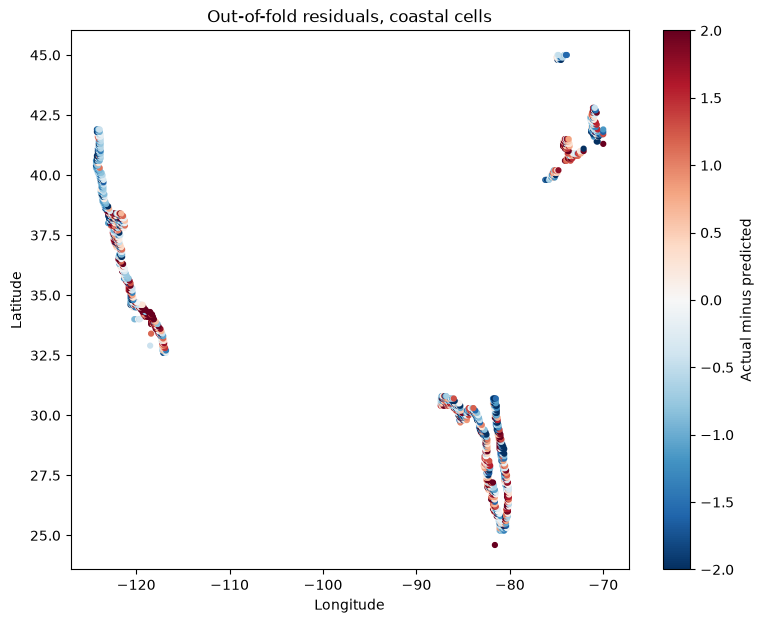

In [5]:
from migracoast_ml.models.evaluate import oof_predictions
from migracoast_ml.models.ladder import build_models

table["oof"] = oof_predictions(
    table[list(FEATURE_NAMES)], table["target"], table["block"],
    build_models()[metadata["winner"]],
)
table["residual"] = table["target"] - table["oof"]

coastal = table[table["coast_km"] < 30]
plt.figure(figsize=(9, 7))
plt.scatter(coastal["cell_lon"], coastal["cell_lat"],
            c=coastal["residual"], cmap="RdBu_r", s=12,
            vmin=-2, vmax=2)
plt.colorbar(label="Actual minus predicted")
plt.title("Out-of-fold residuals, coastal cells")
plt.xlabel("Longitude"); plt.ylabel("Latitude")

Text(0.5, 1.0, 'Out-of-fold predictions, coastal cells')

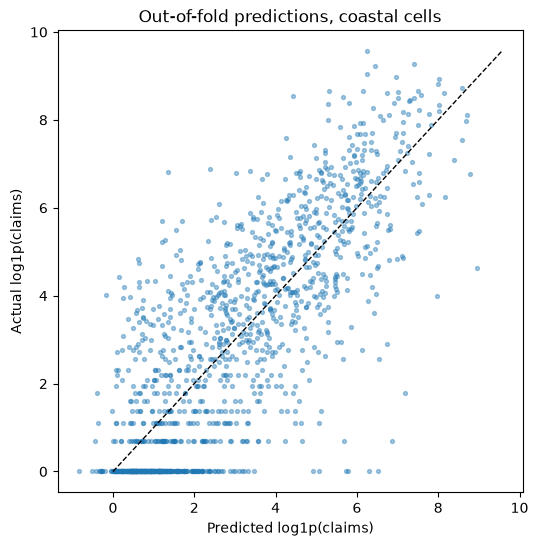

In [6]:
plt.figure(figsize=(6, 6))
plt.scatter(coastal["oof"], coastal["target"], s=8, alpha=0.4)
limit = max(coastal["target"].max(), coastal["oof"].max())
plt.plot([0, limit], [0, limit], "k--", lw=1)
plt.xlabel("Predicted log1p(claims)"); plt.ylabel("Actual log1p(claims)")
plt.title("Out-of-fold predictions, coastal cells")

In [7]:
from migracoast_ml.baseline import run_comparison
print(run_comparison())

Matched cells: 34 of 480 scored rows
Alignment confidence (rule score vs elevation): -0.235
ALIGNMENT REJECTED. The reconstructed coordinates do not track elevation as a higher-is-safer score must. The comparison is not reported, because publishing it would mean trusting a mapping the data contradicts.


## Limitations

The target is claim count, not flood probability. A cell with many claims may
simply hold many insured buildings, because the public data has no policy
count to divide by. The model predicts claim intensity and should be read as
such. Coordinates are rounded by FEMA to 0.1 degrees, which fixes the
resolution at roughly 11 km. Storm and flood counts cover 2000 to 2024 only.